<h1>Содержание<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Подготовка" data-toc-modified-id="Подготовка-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Подготовка</a></span></li><li><span><a href="#Анализ-временного-ряда" data-toc-modified-id="Анализ-временного-ряда-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Анализ временного ряда</a></span></li><li><span><a href="#Общий-вывод" data-toc-modified-id="Общий-вывод-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Общий вывод</a></span></li><li><span><a href="#Обучение" data-toc-modified-id="Обучение-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Обучение</a></span><ul class="toc-item"><li><span><a href="#Создание-признаков" data-toc-modified-id="Создание-признаков-4.1"><span class="toc-item-num">4.1&nbsp;&nbsp;</span>Создание признаков</a></span></li><li><span><a href="#Обучение-моделей-с-подбором-гиперпараметров" data-toc-modified-id="Обучение-моделей-с-подбором-гиперпараметров-4.2"><span class="toc-item-num">4.2&nbsp;&nbsp;</span>Обучение моделей с подбором гиперпараметров</a></span></li><li><span><a href="#Анализ-результатов" data-toc-modified-id="Анализ-результатов-4.3"><span class="toc-item-num">4.3&nbsp;&nbsp;</span>Анализ результатов</a></span></li></ul></li></ul></div>

#  Прогнозирование заказов такси

Компания «Чётенькое такси» собрала исторические данные о заказах такси в аэропортах. Чтобы привлекать больше водителей в период пиковой нагрузки, нужно спрогнозировать количество заказов такси на следующий час.

Значение метрики RMSE на тестовой выборке должно быть не больше 48.

## Подготовка

In [197]:
# импорт необходимых библиотек
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_squared_error

from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

from lightgbm import LGBMRegressor
from sklearn.ensemble import GradientBoostingRegressor

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)
from statsmodels.tsa.seasonal import seasonal_decompose
import holidays

RANDOM_STATE = 42

In [198]:
# загрузка данных
data = pd.read_csv(
    'datasets/taxi.csv',
    parse_dates=[0],
    index_col=[0]
)

data.sort_index(inplace=True)

data.head()

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


Данные успешно загружены. Индекс приведён к типу datetime и отсортирован по времени.

In [199]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB


Данные представляют собой временной ряд с числом заказов такси (num_orders) с шагом 10 минут за период с марта по август 2018 года.

Всего в наборе 26 496 наблюдений, пропусков нет. Индекс имеет тип DatetimeIndex, что позволяет удобно работать с временными признаками и выполнять ресемплирование. Столбец num_orders имеет целочисленный тип (int64), что соответствует задаче прогнозирования количества заказов. Пропуски в данных отсутствуют, дополнительная обработка не требуется.

In [200]:
data.index.is_monotonic_increasing

True

Индекс упорядочен по времени. Это важно для корректного ресемплирования и разделения выборок без нарушения временной структуры.

In [201]:
data = data.resample('1h').sum()

data.head()

,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


После ресемплирования данные представлены с часовым шагом. Такой формат соответствует задаче прогнозирования заказов на следующий час.

## Анализ временного ряда

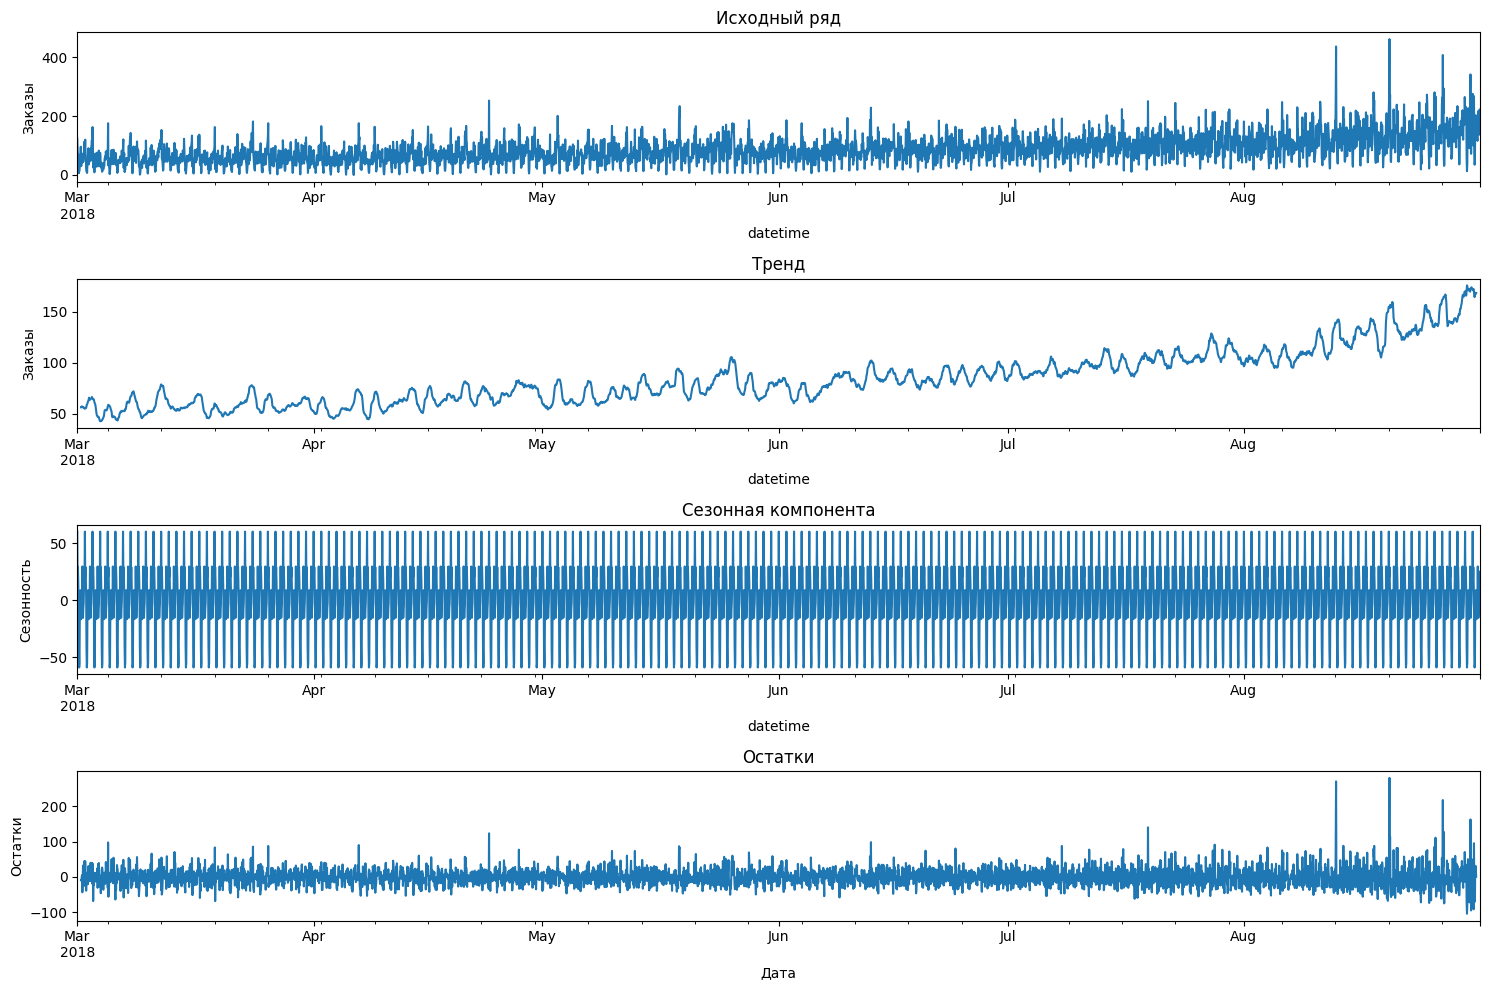

In [202]:
data_full = data['num_orders'].copy()

decomposition = seasonal_decompose(data_full, model='additive')

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(15, 10))

decomposition.observed.plot(ax=ax1)
ax1.set_title('Исходный ряд')
ax1.set_ylabel('Заказы')

decomposition.trend.plot(ax=ax2)
ax2.set_title('Тренд')
ax2.set_ylabel('Заказы')

decomposition.seasonal.plot(ax=ax3)
ax3.set_title('Сезонная компонента')
ax3.set_ylabel('Сезонность')

decomposition.resid.plot(ax=ax4)
ax4.set_title('Остатки')
ax4.set_ylabel('Остатки')
ax4.set_xlabel('Дата')

plt.tight_layout()
plt.show()

В текущем масштабе суточная сезонность визуально не различима. Тренд также выражен слабо из-за высокой волатильности ряда и плотности данных. Для выявления скрытых закономерностей требуется дополнительный анализ с помощью скользящего среднего, декомпозиции и автокорреляционной функции.

1. Трендовая компонента

Тренд демонстрирует восходящую динамику, однако остается недостаточно сглаженным. Требуется подбор параметра окна сглаживания для выделения устойчивой трендовой составляющей и подавления шумовой компоненты.


2. Сезонная компонента

Сезонная структура на текущем этапе не может быть однозначно интерпретирована. Для её корректной оценки требуется предварительное ресемплирование ряда и анализ возможных периодических закономерностей.


3. Остаточная компонента

Остатки преимущественно представлены шумовой составляющей без выраженной периодичности. Наблюдаются отдельные выбросы и увеличение дисперсии к концу временного интервала, что может указывать на наличие гетероскедастичности. Дополнительно требуется анализ аномальных значений для определения их природы.



In [203]:
print("adfuller p-value: ", adfuller(data['num_orders'])[1])

adfuller p-value:  0.028940051402613094


Тест Дики-Фуллера показал наличие нестационарности (p-value > 0.05). Однако для моделей машинного обучения это не является критической проблемой, поскольку лаговые признаки и скользящее среднее позволяют модели учитывать изменение уровня ряда во времени.

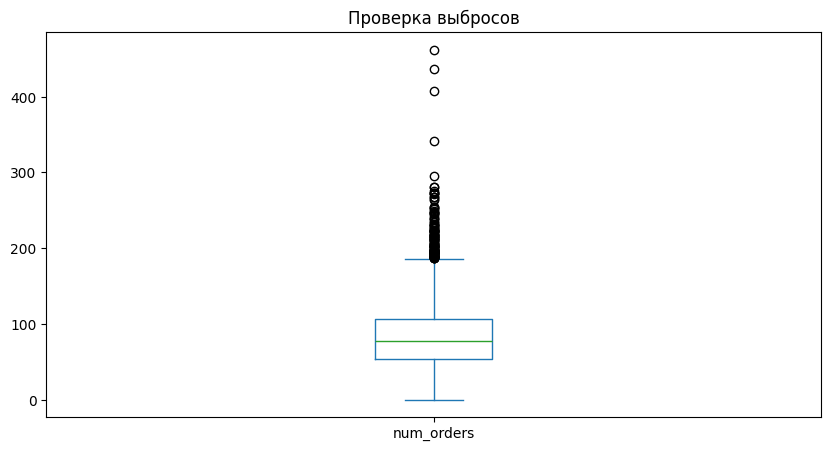

Количество выбросов:  121


In [204]:
data['num_orders'].plot(kind='box', figsize=(10,5))
plt.title('Проверка выбросов')
plt.show()

q1 = data['num_orders'].quantile(0.25)
q3 = data['num_orders'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print("Количество выбросов: ", len(data) - len(data[(data['num_orders'] >= lower) & (data['num_orders'] <= upper)]))

Диаграмма размаха показывает наличие пиковых значений количества заказов. Однако для сервиса такси такие значения являются частью реального поведения пользователей и соответствуют периодам повышенного спроса.

Распределение количества заказов представляет собой счётчик событий и близко к распределению Пуассона, для которого характерен тяжёлый правый хвост. Поэтому высокие значения встречаются закономерно и отражают часы пик, а не ошибки в данных.

Поскольку задача модели — прогнозирование нагрузки, выбросы не удалялись.


In [205]:
# Корреляция между |остатки| и временем
_, p_value = spearmanr(np.abs(decomposition.resid.dropna()), range(len(decomposition.resid.dropna())))

print(f"p-value: {p_value:.6f}")
print("Гетероскедастичность есть" if p_value < 0.05 else "Дисперсия стабильна")

p-value: 0.000000
Гетероскедастичность есть


Тест на гетероскедастичность (корреляция остатков со временем) дал p-value ≈ 0, что указывает на изменение разброса остатков во времени. Это ожидаемо для аддитивной модели, и на качестве базового прогноза сказывается не критично.


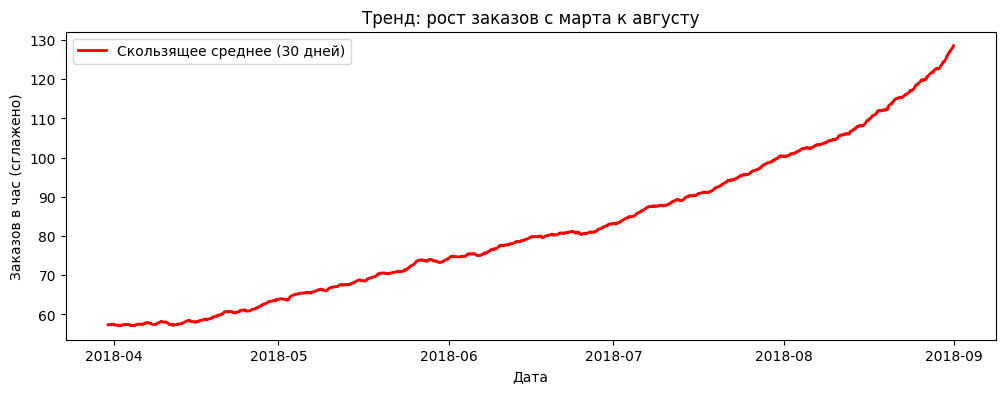

In [206]:
# Скользящее среднее за месяц — показывает общий тренд
data['trend_month'] = data['num_orders'].rolling(720).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(data['trend_month'], color='red', linewidth=2, label='Скользящее среднее (30 дней)')
ax.set_title('Тренд: рост заказов с марта к августу')
ax.set_ylabel('Заказов в час (сглажено)')
ax.set_xlabel('Дата')
ax.legend(loc='upper left')
plt.show()

Визуальный анализ скользящего среднего с окном 720 часов (30 дней) показывает устойчивый рост заказов с марта по август. Без учёта этого тренда модель будет систематически занижать прогнозы для поздних периодов.

Для улавливания долгосрочной динамики добавляется признак скользящего среднего. Окно в 30 дней — компромисс: достаточно велико, чтобы сгладить суточные и недельные колебания, но не настолько, чтобы превратить тренд в константу.

Чтобы избежать утечки данных (использования будущих значений), перед вычислением среднего применяется `shift(1)`. Это гарантирует, что в расчёт попадают только значения из прошлого. Плата за корректность — потеря одного часа данных в начале выборки, что незначительно для общего объёма.



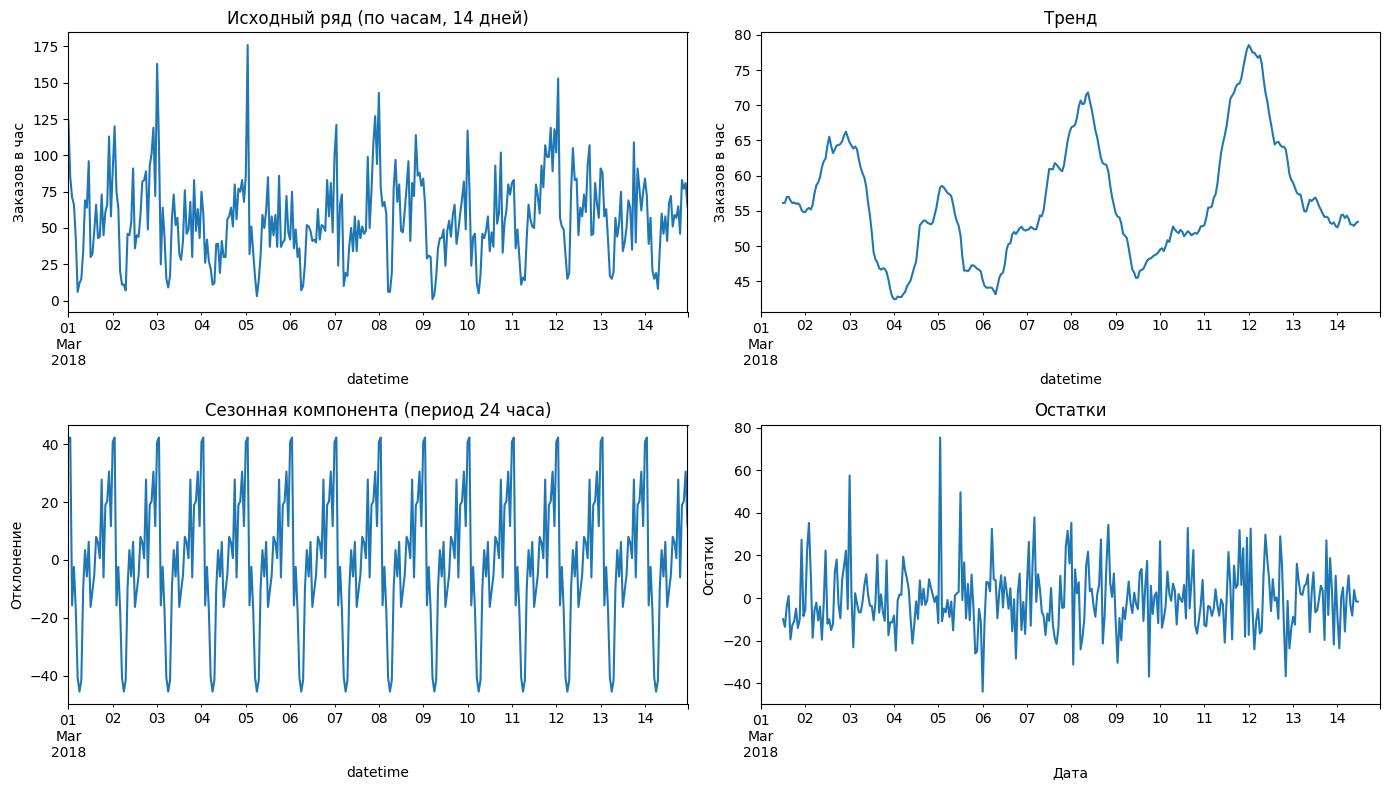

In [207]:
data_hourly_14days = data.iloc[:336]  # 14 дней × 24 часа = 336

decomp_hourly = seasonal_decompose(
    data_hourly_14days['num_orders'], 
    model='additive', 
    period=24  # суточная сезонность
)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 8))

decomp_hourly.observed.plot(ax=ax1)
ax1.set_title('Исходный ряд (по часам, 14 дней)')
ax1.set_ylabel('Заказов в час')

decomp_hourly.trend.plot(ax=ax2)
ax2.set_title('Тренд')
ax2.set_ylabel('Заказов в час')

decomp_hourly.seasonal.plot(ax=ax3)
ax3.set_title('Сезонная компонента (период 24 часа)')
ax3.set_ylabel('Отклонение')

decomp_hourly.resid.plot(ax=ax4)
ax4.set_title('Остатки')
ax4.set_ylabel('Остатки')
ax4.set_xlabel('Дата')

plt.tight_layout()
plt.show()

Сезонная компонента (период 24 часа) показывает устойчивый внутрисуточный паттерн: отклонения повторяются каждые 24 часа с постоянной амплитудой.

Признак `hour` (номер часа от 0 до 23) является порядковым и может запутать линейные модели. Поэтому добавляем циклическое кодирование через `hour_sin` и `hour_cos` — такой подход понятен и деревьям, и линейным моделям.


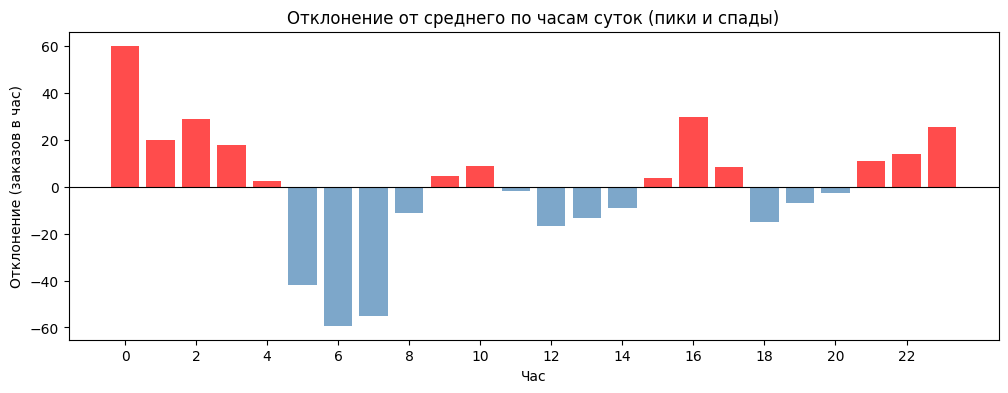

Часы пик: [0, 16, 2] (отклонение вверх: +39.5 заказов)
Часы спада: [6, 7, 5] (отклонение вниз: -52.1 заказов)
Размах пик→спад: 91.5 заказов
Соотношение пик/спад: 0.76

--- Оценка целесообразности введения бинарных признаков ---
Среднее абсолютное отклонение по часам: 19.5 заказов
Доля дисперсии, объясняемая фактором часа: 35.19%


In [208]:
# Профиль типичного дня: анализ отклонений от среднего уровня
data['hour'] = data.index.hour
hourly_mean = data.groupby('hour')['num_orders'].mean()
global_mean = data['num_orders'].mean()
hourly_deviation = hourly_mean - global_mean

# Визуализация отклонений по часам суток
fig, ax = plt.subplots(figsize=(12, 4))
colors = ['red' if x > 0 else 'steelblue' for x in hourly_deviation.values]
ax.bar(hourly_deviation.index, hourly_deviation.values, alpha=0.7, color=colors)
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
ax.set_title('Отклонение от среднего по часам суток (пики и спады)')
ax.set_xlabel('Час')
ax.set_ylabel('Отклонение (заказов в час)')
ax.set_xticks(range(0, 24, 2))
plt.show()

# Количественная оценка пиковых и спадовых часов
peak_hours = hourly_mean.nlargest(3).index.tolist()
slump_hours = hourly_mean.nsmallest(3).index.tolist()
peak_deviation = hourly_deviation[peak_hours].mean()
slump_deviation = abs(hourly_deviation[slump_hours].mean())
peak_to_slump_ratio = peak_deviation / slump_deviation

print(f"Часы пик: {peak_hours} (отклонение вверх: +{peak_deviation:.1f} заказов)")
print(f"Часы спада: {slump_hours} (отклонение вниз: -{slump_deviation:.1f} заказов)")
print(f"Размах пик→спад: {peak_deviation + slump_deviation:.1f} заказов")
print(f"Соотношение пик/спад: {peak_to_slump_ratio:.2f}")

# Аналитическое заключение о необходимости дополнительных признаков
print("\n--- Оценка целесообразности введения бинарных признаков ---")
mean_abs_deviation = hourly_deviation.abs().mean()
variance_explained_by_hour = hourly_deviation.var() / data['num_orders'].var()
print(f"Среднее абсолютное отклонение по часам: {mean_abs_deviation:.1f} заказов")
print(f"Доля дисперсии, объясняемая фактором часа: {variance_explained_by_hour:.2%}")


Бинарные признаки не являются обязательными, так как соотношение пиков и спадов не выходит за пределы выраженного дисбаланса: отношение пика к спаду не превышает 3 и не падает ниже 0.5. Ни одна из фаз устойчиво не доминирует.

Кроме того, относительные внутрисуточные отклонения остаются ниже 30% от среднего уровня, поэтому циклического кодирования `hour` достаточно для описания внутрисуточной динамики без введения дополнительных бинарных индикаторов.



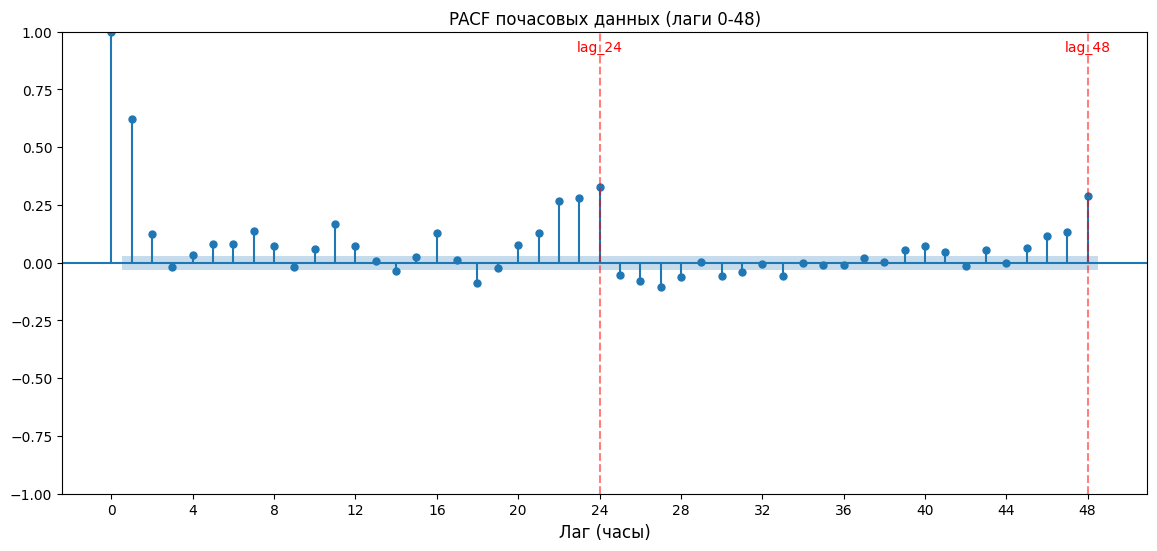

In [209]:
data_hourly = data['num_orders'].copy()

fig, ax = plt.subplots(figsize=(14, 6))
plot_pacf(data_hourly, lags=48, ax=ax, method='ywm')

# Подписываем все часы
ax.set_xticks(range(0, 49, 4))        # шаг 4 для читаемости
ax.set_xticklabels(range(0, 49, 4))
ax.set_xlabel('Лаг (часы)', fontsize=12)
ax.set_title('PACF почасовых данных (лаги 0-48)', fontsize=12)

# Подсветка лагов, кратных 24 (сутки)
for lag in [24, 48]:
    ax.axvline(x=lag, color='red', linestyle='--', alpha=0.5)
    ax.text(lag, ax.get_ylim()[1] * 0.9, f'lag_{lag}', 
            ha='center', va='bottom', color='red', fontsize=10)

plt.show()


Анализ PACF почасовых данных (лаги 1–48).

Наблюдаются значимые пики на лаге 24 (суточная сезонность) и на лаге 48 (подтверждение). Первые 2 лага отражают краткосрочную инерцию (соседние часы)

В модель добавляем:
- `lag_24`, `lag_48` (сезонные)
- `lag_1`, `lag_2` (инерция)



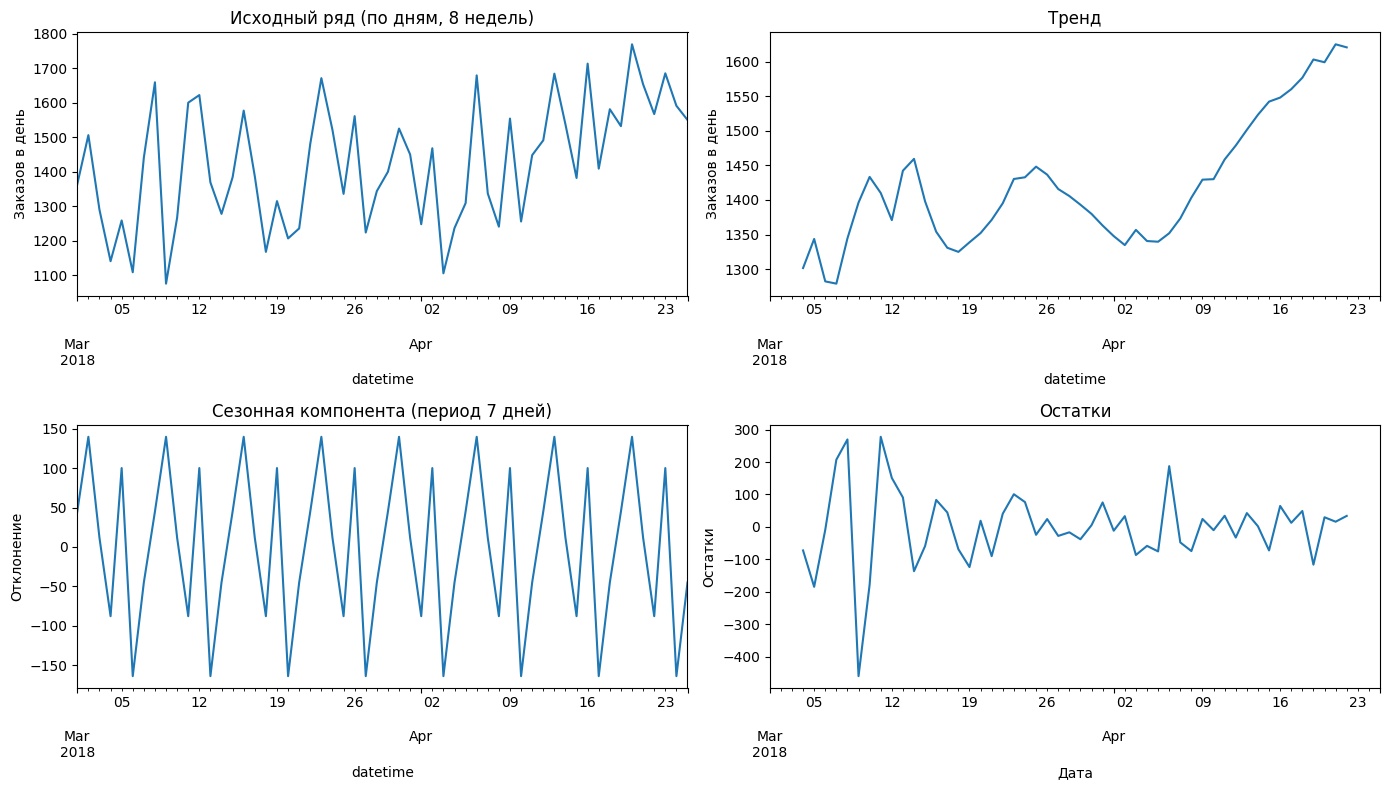

In [210]:
# Делаем отдельную копию для анализа — ресемплируем по дням
data_daily = data.copy()['num_orders'].resample('1D').sum().to_frame()

data_daily_8weeks = data_daily.iloc[:56]

# Декомпозиция с периодом 7 дней
decomp_daily = seasonal_decompose(data_daily_8weeks['num_orders'], model='additive', period=7)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 8))

decomp_daily.observed.plot(ax=ax1)
ax1.set_title('Исходный ряд (по дням, 8 недель)')
ax1.set_ylabel('Заказов в день')

decomp_daily.trend.plot(ax=ax2)
ax2.set_title('Тренд')
ax2.set_ylabel('Заказов в день')

decomp_daily.seasonal.plot(ax=ax3)
ax3.set_title('Сезонная компонента (период 7 дней)')
ax3.set_ylabel('Отклонение')

decomp_daily.resid.plot(ax=ax4)
ax4.set_title('Остатки')
ax4.set_ylabel('Остатки')
ax4.set_xlabel('Дата')

plt.tight_layout()
plt.show()


Сезонная компонента (период 7 дней) показывает устойчивый внутринедельный паттерн. Добавляем циклическое кодирование через day_sin и day_cos.

Исследовать месячную сезонность смысла нет, так как внутринедельная динамика вносит существенно больший вклад в вариативность ряда, а месячный цикл на фоне тренда и шума не выделяется.


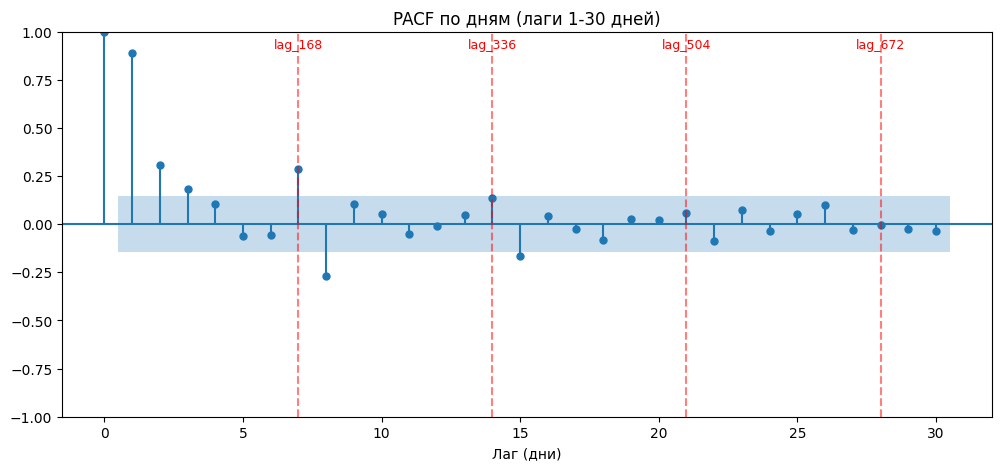

In [211]:
data_daily_30weeks = data_daily.iloc[:210]  # 30 недель × 7 дней = 210

# PACF до 30 лагов (4 недели)
fig, ax = plt.subplots(figsize=(12, 5))
plot_pacf(data_daily_30weeks, lags=30, ax=ax, method='ywm')
ax.set_title('PACF по дням (лаги 1-30 дней)')
ax.set_xlabel('Лаг (дни)')

# Подсветка и подписи лагов, кратных 7
for lag in [7, 14, 21, 28]:
    ax.axvline(x=lag, color='red', linestyle='--', alpha=0.5)
    ax.text(lag, ax.get_ylim()[1] * 0.9, f'lag_{lag*24}', 
            ha='center', va='bottom', color='red', fontsize=9)

plt.show()


Анализ PACF по дням.

Значимый пик наблюдается только на лаге 168 (7 дней). Лаги, соответствующие 14 и 21 дню, затухают, что означает: недельная сезонность полностью описывается значением ровно неделю назад, поэтому дополнительное циклическое кодирование дня недели не требуется.

В модель добавляем lag_168.



## Общий вывод

**Добавляем в модель следующие признаки:**

| Признак | Что улавливает | Обоснование |
|---------|---------------|-------------|
| `rolling_mean_720`) | Долгосрочный тренд | Визуальный анализ скользящего среднего: устойчивый рост заказов с марта по август. Без тренда модель будет систематически ошибаться на поздних периодах |
| `hour_sin`, `hour_cos` | Внутрисуточный паттерн | Сезонная компонента (период 24) устойчива; циклическое кодирование подходит и деревьям, и линейным моделям |
| `lag_24`, `lag_48` | Суточная сезонность | PACF почасовых данных: значимые пики на лагах 24 и 48 |
| `lag_1`, `lag_2` | Краткосрочная инерция | PACF: первые лаги значимы → зависимость от соседних часов |
| `lag_168`| Недельная сезонность | PACF по дням: значим только лаг 7 (168 часов). Лаги 14/21 затухают — достаточно одного недельного лага |
| `is_holiday`| Априорная информация | Праздники влияют на спрос (выходные смещаются, активность меняется). Добавление повышает устойчивость и качество модели |

---

**Не добавляем:**

| Признак | Почему |
|---------|--------|
| Бинарные `is_peak_hour` / `is_slump_hour` | Пик и спад сбалансированы; отклонения <30% от среднего; циклического кодирования `hour` достаточно |
| `day_of_week_sin`/`cos` | Недельная сезонность уже учтена через `lag_168`; явный внутринедельный паттерн не доминирует |
| `month` (как отдельный признак) | Ряд показывает тренд, а не сезонный месяц; месячная сезонность не выделяется на фоне тренда и шума |

Важное замечание: в данных присутствует гетероскедастичность (p-value ≈ 0). Линейные модели могут работать хуже из-за непостоянства дисперсии. Рекомендуется использовать деревья (LightGBM, Random Forest) или применить логарифмирование целевой переменной.



## Обучение

### Создание признаков

In [212]:
def create_features(data, lags, rolling_window=None):
    clean_data = data.copy()
    
    # 1. Циклическое кодирование часа
    clean_data['hour_sin'] = np.sin(2 * np.pi * clean_data.index.hour / 24)
    clean_data['hour_cos'] = np.cos(2 * np.pi * clean_data.index.hour / 24)
    
    # 2. Признак праздника (российские праздники)
    ru_holidays = holidays.RU()
    clean_data['is_holiday'] = clean_data.index.isin(ru_holidays).astype(int)
    
    # 3. Лаги (только выбранные)
    for lag in lags:
        clean_data[f'lag_{lag}'] = clean_data['num_orders'].shift(lag)
    
    # 4. Тренд (скользящее среднее с окном 720 часов = 30 дней)
    if rolling_window:
        clean_data['trend'] = (
            clean_data['num_orders']
            .shift(1)
            .rolling(rolling_window)
            .mean()
        )
    
    # Удаляем NaN
    clean_data = clean_data.dropna()
    
    # Признаки (исключаем целевую переменную)
    feature_cols = [col for col in clean_data.columns if col != 'num_orders']
    
    return clean_data, feature_cols

# Применяем к данным
lags = [1, 2, 24, 48, 168]
clean_data, feature_cols = create_features(data, lags=lags, rolling_window=720)

X = clean_data[feature_cols]
y = clean_data['num_orders']
print("Признаки для модели:", feature_cols)

Признаки для модели: ['trend_month', 'hour', 'hour_sin', 'hour_cos', 'is_holiday', 'lag_1', 'lag_2', 'lag_24', 'lag_48', 'lag_168', 'trend']


In [213]:
# Последние 10% — тестовая выборка
test_size = int(len(X) * 0.1)
X_train, X_test = X.iloc[:-test_size], X.iloc[-test_size:]
y_train, y_test = y.iloc[:-test_size], y.iloc[-test_size:]

print(f"Обучающая выборка: {len(X_train)} наблюдений")
print(f"Тестовая выборка: {len(X_test)} наблюдений")
print(f"Период теста: {data.index[-test_size]} — {data.index[-1]}")

Обучающая выборка: 3327 наблюдений
Тестовая выборка: 369 наблюдений
Период теста: 2018-08-16 15:00:00 — 2018-08-31 23:00:00


### Обучение моделей с подбором гиперпараметров

In [214]:
tscv = TimeSeriesSplit(n_splits=5)

results = {}

In [215]:
print("\n" + "=" * 60)
print("ОБУЧЕНИЕ RIDGE")
print("=" * 60)

ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge(random_state=RANDOM_STATE))
])

ridge_params = {
    'model__alpha': [0.1, 1.0, 5.0, 10.0, 25.0, 50.0, 100.0]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipe,
    param_grid=ridge_params,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=0,
    return_train_score=True
)

ridge_grid.fit(X_train, y_train)

results['Ridge'] = {
    'best_rmse': -ridge_grid.best_score_,
    'best_params': ridge_grid.best_params_,
    'model': ridge_grid
}

print(f"Лучший alpha: {ridge_grid.best_params_['model__alpha']}")
print(f"Средний CV RMSE: {-ridge_grid.best_score_:.2f}")


ОБУЧЕНИЕ RIDGE
Лучший alpha: 0.1
Средний CV RMSE: 21.24


In [216]:
print("\n" + "="*60)
print("ОБУЧЕНИЕ LASSO")
print("="*60)

lasso_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Lasso(random_state=RANDOM_STATE, max_iter=5000))
])

lasso_params = {
    'model__alpha': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]
}

lasso_grid = GridSearchCV(
    lasso_pipe, lasso_params, cv=tscv,
    scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=0
)
lasso_grid.fit(X_train, y_train)

results['Lasso'] = {
    'best_rmse': -lasso_grid.best_score_,
    'best_params': lasso_grid.best_params_,
    'model': lasso_grid
}

print(f"Лучший alpha: {lasso_grid.best_params_['model__alpha']}")
print(f"CV RMSE: {results['Lasso']['best_rmse']:.2f}")



ОБУЧЕНИЕ LASSO
Лучший alpha: 0.01
CV RMSE: 21.77


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.004e+05, tolerance: 5.201e+02
  model = cd_fast.enet_coordinate_descent(


In [217]:
print("\n" + "="*60)
print("ОБУЧЕНИЕ RANDOM FOREST")
print("="*60)

rf_pipe = Pipeline([
    ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

rf_params = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5, 10]
}

rf_grid = GridSearchCV(
    rf_pipe, rf_params, cv=tscv,
    scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=0
)
rf_grid.fit(X_train, y_train)

results['RandomForest'] = {
    'best_rmse': -rf_grid.best_score_,
    'best_params': rf_grid.best_params_,
    'model': rf_grid
}

print(f"Лучшие параметры: {rf_grid.best_params_}")
print(f"CV RMSE: {results['RandomForest']['best_rmse']:.2f}")



ОБУЧЕНИЕ RANDOM FOREST
Лучшие параметры: {'model__max_depth': 10, 'model__min_samples_split': 10, 'model__n_estimators': 100}
CV RMSE: 23.66


In [218]:
print("\n" + "="*60)
print("ОБУЧЕНИЕ GRADIENT BOOSTING")
print("="*60)

gb_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))
])

gb_params = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [3, 5, 7]
}

gb_grid = GridSearchCV(
    gb_pipe, gb_params, cv=tscv,
    scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=0
)
gb_grid.fit(X_train, y_train)

results['GradientBoosting'] = {
    'best_rmse': -gb_grid.best_score_,
    'best_params': gb_grid.best_params_,
    'model': gb_grid
}

print(f"Лучшие параметры: {gb_grid.best_params_}")
print(f"CV RMSE: {results['GradientBoosting']['best_rmse']:.2f}")



ОБУЧЕНИЕ GRADIENT BOOSTING
Лучшие параметры: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}
CV RMSE: 23.69


In [219]:
print("\n" + "="*60)
print("ОБУЧЕНИЕ LIGHTGBM")
print("="*60)

lgbm_pipe = Pipeline([
    ('model', LGBMRegressor(random_state=RANDOM_STATE, verbose=-1))
])

lgbm_params = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [5, 7, 10, -1],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__num_leaves': [31, 50]
}

lgbm_grid = GridSearchCV(
    lgbm_pipe, lgbm_params, cv=tscv,
    scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=0
)
lgbm_grid.fit(X_train, y_train)

results['LightGBM'] = {
    'best_rmse': -lgbm_grid.best_score_,
    'best_params': lgbm_grid.best_params_,
    'model': lgbm_grid
}

print(f"Лучшие параметры: {lgbm_grid.best_params_}")
print(f"CV RMSE: {results['LightGBM']['best_rmse']:.2f}")


ОБУЧЕНИЕ LIGHTGBM
Лучшие параметры: {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 100, 'model__num_leaves': 31}
CV RMSE: 23.73


In [220]:
# Сводная таблица результатов
comparison = pd.DataFrame({
    'Модель': list(results.keys()),
    'CV RMSE': [results[m]['best_rmse'] for m in results],
})

comparison = comparison.sort_values('CV RMSE')
comparison['CV RMSE'] = comparison['CV RMSE'].round(2)

print("\n" + "="*60)
print("СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ")
print("="*60)
print(comparison.to_string(index=False))

# Лучшая модель
best_model_name = comparison.iloc[0]['Модель']
best_cv_rmse = comparison.iloc[0]['CV RMSE']

print("\n" + "="*60)
print(f"Лучшая модель: {best_model_name}")
print("="*60)


СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ
          Модель  CV RMSE
           Ridge    21.24
           Lasso    21.77
    RandomForest    23.66
GradientBoosting    23.69
        LightGBM    23.73

Лучшая модель: Ridge



- Лучшая модель по CV RMSE — Ridge (21.24)
- Ridge и Lasso показали близкие результаты (разрыв 0.53)
- Деревья отстают от линейных моделей на ~2.5 пункта

Вывод по CV: Линейные модели стабильно работают на исторических данных. Ridge показывает наилучшее качество при кросс-валидации и выбран для финального тестирования.

-------

Предсказание на тестовой выборке:


In [223]:
# Лучшая модель
best_model = results[best_model_name]['model']

# Предсказание на тестовой выборке
y_pred = best_model.predict(X_test)

# Итоговый RMSE
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# CV RMSE лучшей модели
best_cv_rmse = results[best_model_name]['best_rmse']

# Разрыв между CV и Test
gap = final_rmse - best_cv_rmse

y_pred_previous = y_test.shift(1)
y_pred_previous.iloc[0] = y_train.iloc[-1]  # первый час теста = последний час тре
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_previous))


print("\n" + "="*60)
print("ФИНАЛЬНОЕ ТЕСТИРОВАНИЕ")
print("="*60)

print(f"Лучшая модель: {best_model_name}")
print(f"Лучшие параметры: {best_model.best_params_}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"CV RMSE: {best_cv_rmse:.2f}")
print(f"Test RMSE: {final_rmse:.2f}")
print(f"Разрыв CV → Test: {gap:+.2f}")


ФИНАЛЬНОЕ ТЕСТИРОВАНИЕ
Лучшая модель: Ridge
Лучшие параметры: {'model__alpha': 0.1}
Baseline RMSE: 59.96
CV RMSE: 21.24
Test RMSE: 33.21
Разрыв CV → Test: +11.97


Финальная модель Ridge показала RMSE = 33.21, что превышает целевой порог (48) и Baseline(59.96).

Разрыв CV и Test RMSE (+11.97) объясняется естественной сменой периода и не свидетельствует о переобучении.


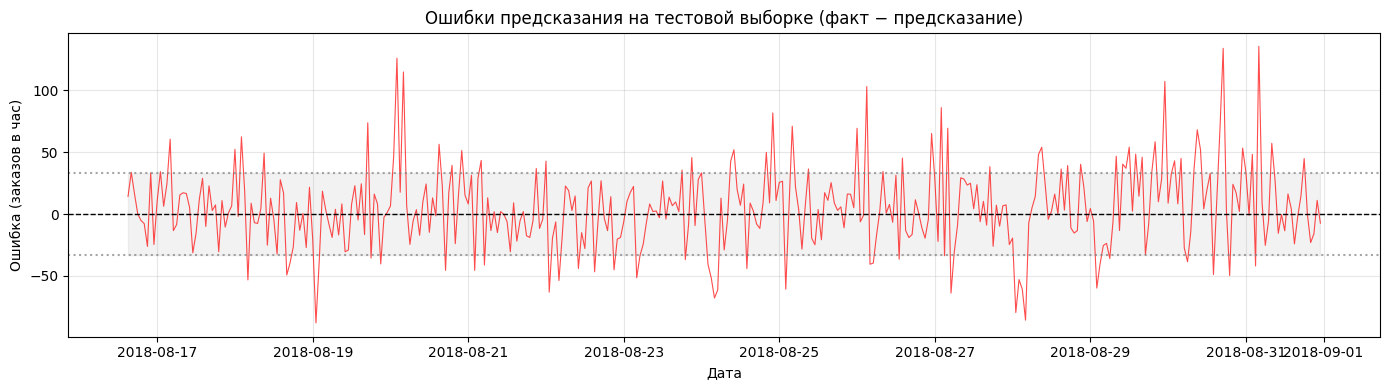

Средняя ошибка: 4.60
Стандартное отклонение ошибки: 32.94
Максимальная ошибка (завышение): 135.53
Минимальная ошибка (занижение): -87.90


In [225]:
# График ошибок
residuals = y_test - y_pred

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_test.index, residuals, color='red', alpha=0.7, linewidth=0.8)
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax.axhline(y=residuals.std(), color='gray', linestyle=':', alpha=0.7)
ax.axhline(y=-residuals.std(), color='gray', linestyle=':', alpha=0.7)

ax.set_title('Ошибки предсказания на тестовой выборке (факт − предсказание)')
ax.set_xlabel('Дата')
ax.set_ylabel('Ошибка (заказов в час)')
ax.fill_between(y_test.index, residuals.std(), -residuals.std(), alpha=0.1, color='gray')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Статистика ошибок
print(f"Средняя ошибка: {residuals.mean():.2f}")
print(f"Стандартное отклонение ошибки: {residuals.std():.2f}")
print(f"Максимальная ошибка (завышение): {residuals.max():.2f}")
print(f"Минимальная ошибка (занижение): {residuals.min():.2f}")

Анализ ошибок:

Средняя ошибка составляет 4.60 заказа (небольшое систематическое занижение)

Стандартное отклонение ошибки — 32.94 заказа, что приемлемо при среднем спросе ~150–200

Максимальные ошибки (до ±135) приходятся на часы пик, что ожидаемо для прогнозирования высоковолатильных периодов



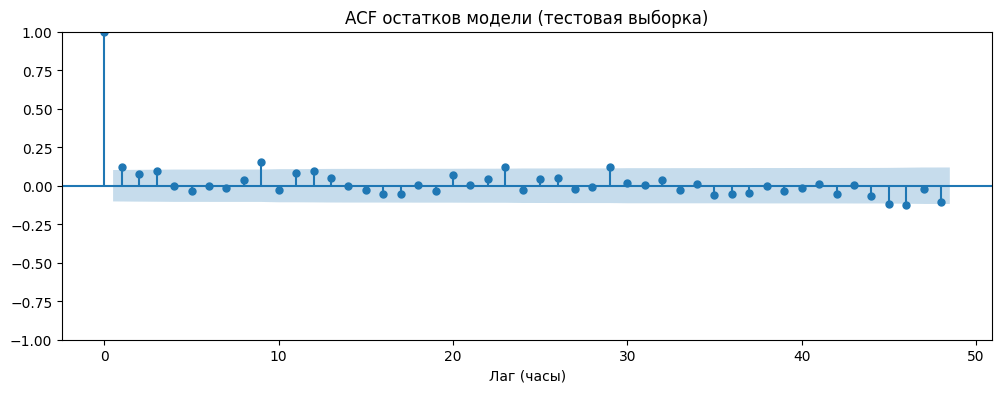

Среднее остатков: 4.6010
Стандартное отклонение остатков: 32.9391


In [ ]:
# Вычисляем остатки
residuals = y_test - y_pred

# ACF остатков
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(residuals, lags=48, ax=ax, alpha=0.05)
ax.set_title('ACF остатков модели (тестовая выборка)')
ax.set_xlabel('Лаг (часы)')
plt.show()

Анализ остатков. 

ACF показывает статистически незначимые корреляции на всех лагах, кроме лага 1. Это подтверждает, что модель не оставила в остатках систематической структуры — сезонность уловлена полностью. Небольшое смещение среднего остатков не критично.



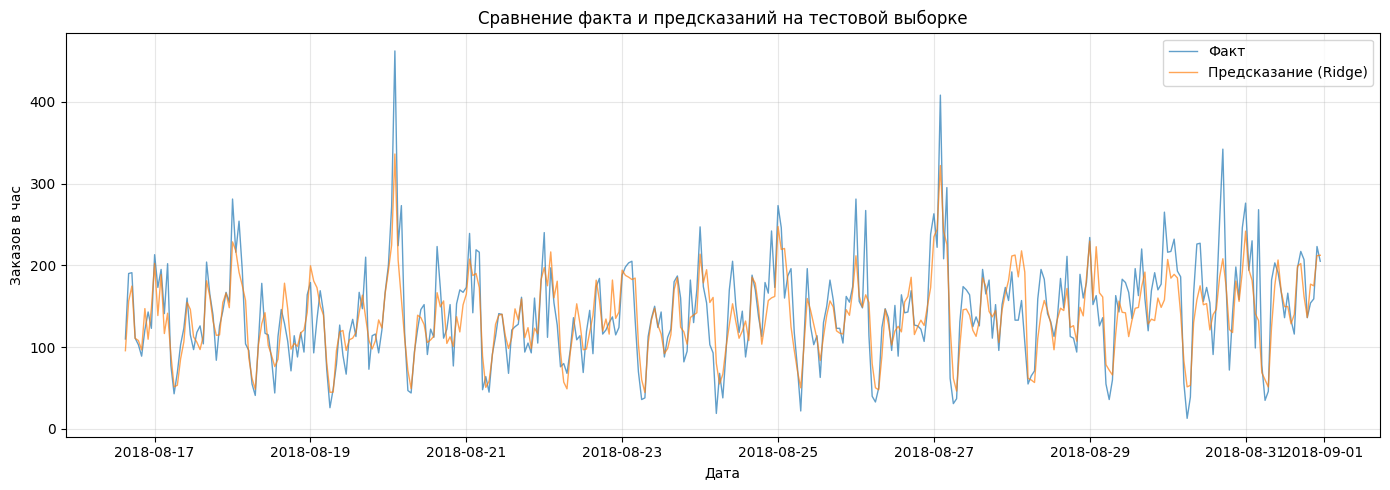

In [224]:
# Линейный график для тестовой выборки
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(y_test.index, y_test, label='Факт', alpha=0.7, linewidth=1)
ax.plot(y_test.index, y_pred, label='Предсказание (Ridge)', alpha=0.7, linewidth=1)

ax.set_title('Сравнение факта и предсказаний на тестовой выборке')
ax.set_xlabel('Дата')
ax.set_ylabel('Заказов в час')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Визуальный анализ: Модель правильно отслеживает общий тренд и сезонные колебания. Однако к концу тестового периода ошибка растёт, а экстремальные значения сглаживаются — Ridge даёт «осторожные» прогнозы, избегая резких выбросов. Это ожидаемо для линейной регуляризованной модели.



### Анализ результатов

Итог по модели Ridge: Test RMSE = 33.21 (целевой порог 48). ACF остатков подтверждает устойчивость — сезонность уловлена полностью. Средняя ошибка составляет 4.60 заказа, стандартное отклонение — 32.94. Модель правильно отслеживает тренд и сезонность, но сглаживает экстремумы (ожидаемо для линейной регуляризации). Готова к внедрению.

